# Esercitazione 3 — Support Vector Machine (SVM) con kernel RBF

Una SVM cerca l'**iperpiano** che separa le classi con il **margine massimo**. Col **kernel trick** (qui il kernel gaussiano **RBF**)
può separare dati non linearmente separabili:

$$K(x, x') = \exp(-\gamma \lVert x - x' \rVert^2)$$

Iperparametri principali:
- **C** = 1.0: penalità per gli errori (C alto → margine stretto, rischio overfitting; C basso → margine largo, più tolleranza);
- **gamma** = `'scale'` (= $1/(n_{features} \cdot Var(X))$): raggio di influenza di ogni punto.

L'SVM è basata sulle distanze → **lo scaling è indispensabile**.

Svolgeremo due casi: **Breast Cancer** (binaria) e **Iris** (multiclasse, strategia One-vs-One).

## 0. Setup e importazioni

In [1]:
# Import delle librerie di base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Moduli di scikit-learn
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # seme fisso per la riproducibilità

## Parte A — Classificazione binaria: Breast Cancer

### 1. Caricamento
569 campioni, 30 feature numeriche; classi: `0 = malignant`, `1 = benign`.

In [2]:
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
target_names = cancer.target_names   # ['malignant' 'benign']

print("Shape:", X.shape, "| classi:", dict(zip(target_names, np.bincount(y))))

Shape: (569, 30) | classi: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


### 2. Suddivisione in Training (70%) e Test (30%)

In [3]:
# Split 70% train / 30% test.
# random_state=42 -> risultato riproducibile; stratify=y -> stesse proporzioni di classi in train e test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (398, 30) | Test: (171, 30)


## Feature Scaling con `StandardScaler`

`StandardScaler` trasforma ogni feature in modo che abbia media 0 e deviazione standard 1: $z = (x - \mu)/\sigma$.

**Regola fondamentale:**
1. `fit_transform` sul **training set**: lo scaler *impara* media e deviazione standard dai soli dati di training e li applica.
2. `transform` sul **test set**: si riusano gli stessi $\mu$ e $\sigma$ del training.

Se facessimo `fit` anche sul test (o sull'intero dataset) useremmo informazioni che nella realtà non abbiamo ancora: è il **data leakage**, che rende le stime di performance troppo ottimistiche. Il test set deve simulare dati *mai visti*.

In [4]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)  # fit + transform sul train
X_test_s = scaler.transform(X_test)        # solo transform sul test

### 3. Modello SVC e addestramento
`probability=True` abilita `predict_proba` (calibrazione interna con cross-validation: rallenta un po' il fit).

In [5]:
svm = SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE)
svm.fit(X_train_s, y_train)

y_pred = svm.predict(X_test_s)
y_proba = svm.predict_proba(X_test_s)

print("Numero di support vectors per classe:", dict(zip(target_names, svm.n_support_)))
print("Probabilità (primi 3 campioni):\n", y_proba[:3].round(3))

Numero di support vectors per classe: {np.str_('malignant'): np.int32(49), np.str_('benign'): np.int32(42)}
Probabilità (primi 3 campioni):
 [[0.989 0.011]
 [0.05  0.95 ]
 [0.082 0.918]]


C:\Users\matti\AppData\Local\Temp\claude\C--Users-matti-workspace-Github-usr-exercises\80b71679-4f21-4bc2-aeca-71991051dcbe\scratchpad\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### 4. Valutazione

In [6]:
print(f"Accuracy sul test set: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=target_names))

Accuracy sul test set: 0.9766

              precision    recall  f1-score   support

   malignant       0.97      0.97      0.97        64
      benign       0.98      0.98      0.98       107

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171



### 5. Matrice di confusione

Per leggere TP/FP/FN/TN bisogna dichiarare quale classe è "positiva". Scegliamo `malignant` (la più importante da non perdere): con `labels=[0, 1]` la riga/colonna 0 è la classe positiva.

| | Predetto malignant | Predetto benign |
|---|---|---|
| **Reale malignant** | **TP** (vero positivo) | **FN** (falso negativo — il più grave in ambito clinico!) |
| **Reale benign** | **FP** (falso positivo) | **TN** (vero negativo) |

TP=62  FN=2  FP=2  TN=105


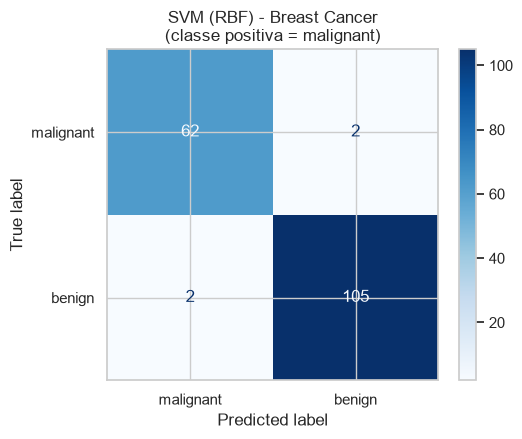

In [7]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])   # 0 = malignant (positiva), 1 = benign
tp, fn, fp, tn = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap="Blues", ax=ax, values_format="d")
ax.set_title("SVM (RBF) - Breast Cancer\n(classe positiva = malignant)")
plt.tight_layout(); plt.show()

## Parte B — Classificazione multiclasse: Iris con strategia One-vs-One (OvO)

`SVC` è nativamente binaria: per K classi usa internamente **One-vs-One**, addestrando $K(K-1)/2$ classificatori binari (per Iris: 3) che poi "votano".
Con `decision_function_shape='ovo'` la `decision_function` espone proprio i punteggi dei classificatori a coppie.

In [8]:
iris = load_iris()
Xi, yi = iris.data, iris.target
names_i = iris.target_names

Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, random_state=RANDOM_STATE, stratify=yi)

sc_i = StandardScaler()
Xi_tr_s = sc_i.fit_transform(Xi_tr)
Xi_te_s = sc_i.transform(Xi_te)

svm_i = SVC(kernel="rbf", C=1.0, gamma="scale", decision_function_shape="ovo",
            probability=True, random_state=RANDOM_STATE)
svm_i.fit(Xi_tr_s, yi_tr)

yi_pred = svm_i.predict(Xi_te_s)
print("Punteggi OvO (decision_function) shape:", svm_i.decision_function(Xi_te_s).shape, "-> 3 classificatori a coppie")
print(f"\nAccuracy: {accuracy_score(yi_te, yi_pred):.4f}\n")
print(classification_report(yi_te, yi_pred, target_names=names_i))

C:\Users\matti\AppData\Local\Temp\claude\C--Users-matti-workspace-Github-usr-exercises\80b71679-4f21-4bc2-aeca-71991051dcbe\scratchpad\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Punteggi OvO (decision_function) shape: (45, 3) -> 3 classificatori a coppie

Accuracy: 0.9333

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



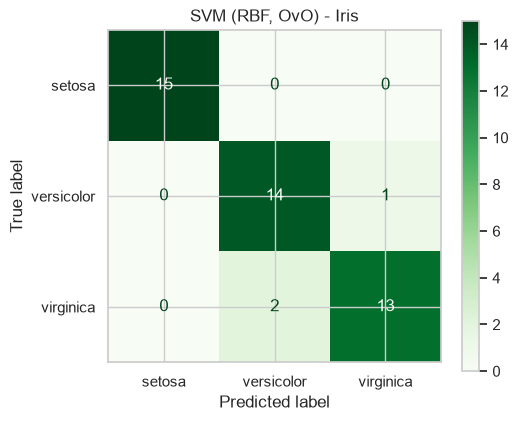

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(yi_te, yi_pred, display_labels=names_i, cmap="Greens", ax=ax)
ax.set_title("SVM (RBF, OvO) - Iris")
plt.tight_layout(); plt.show()

## (Bonus) Effetto di C e gamma
Un rapido sguardo a come cambiano le prestazioni variando gli iperparametri sul dataset Breast Cancer.

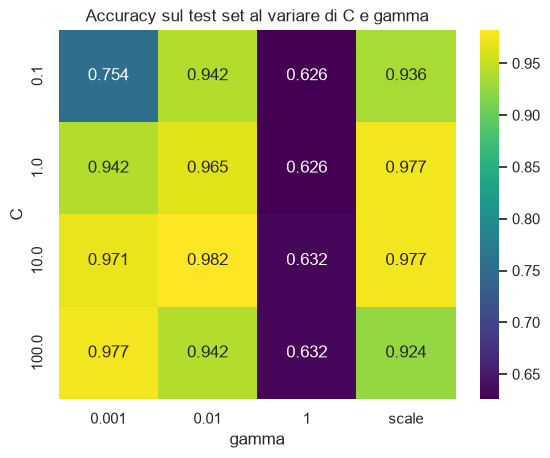

In [10]:
risultati = []
for C in [0.1, 1, 10, 100]:
    for gamma in [0.001, 0.01, "scale", 1]:
        m = SVC(kernel="rbf", C=C, gamma=gamma, random_state=RANDOM_STATE).fit(X_train_s, y_train)
        risultati.append({"C": C, "gamma": str(gamma),
                          "train_acc": m.score(X_train_s, y_train), "test_acc": m.score(X_test_s, y_test)})

res = pd.DataFrame(risultati)
sns.heatmap(res.pivot(index="C", columns="gamma", values="test_acc"), annot=True, fmt=".3f", cmap="viridis")
plt.title("Accuracy sul test set al variare di C e gamma"); plt.show()

## Riepilogo
- Scaling obbligatorio per SVM (fit sul train, transform sul test).
- `SVC(kernel='rbf', C=1.0, gamma='scale')` è un'ottima baseline.
- La matrice di confusione mostra TP, FP, FN, TN: in ambito medico i **falsi negativi** sono l'errore più costoso, quindi oltre all'accuracy guarda **recall** della classe malignant.
- Multiclasse: `SVC` usa One-vs-One internamente.

**Esercizi proposti:** `GridSearchCV` su C e gamma, `class_weight='balanced'`, confronto con `kernel='linear'` e `'poly'`.